<a href="https://colab.research.google.com/github/Dennischegemwangi/code-base/blob/main/Text_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from huggingface_hub import HfApi

api = HfApi()
all_datasets = list(api.list_datasets())
print(f"Total datasets: {len(all_datasets)}")

In [ ]:
from datasets import load_dataset
emotions = load_dataset("dair-ai/emotion")

train_ds = emotions["train"]
train_ds[0]

#print (train_ds.features)
print (train_ds["text"][ :5])

['i didnt feel humiliated', 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake', 'im grabbing a minute to post i feel greedy wrong', 'i am ever feeling nostalgic about the fireplace i will know that it is still on the property', 'i am feeling grouchy']


In [ ]:
#Dataset preprocessing (Data frame)
import pandas as pd
emotions.set_format(type = "pandas")
df = emotions["train"][ : ]
df.tail()

,text,label
15995,i just had a very brief time in the beanbag an...,0
15996,i am now turning and i feel pathetic that i am...,0
15997,i feel strong and good overall,1
15998,i feel like this was such a rude comment and i...,3
15999,i know a lot but i feel so stupid because i ca...,0


In [ ]:
#converting labels to string
def label_int2str(row):
    return emotions ["train"].features["label"].int2str(row)


df["label_name"] = df["label"].apply(label_int2str)
df.head()

,text,label,label_name
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger


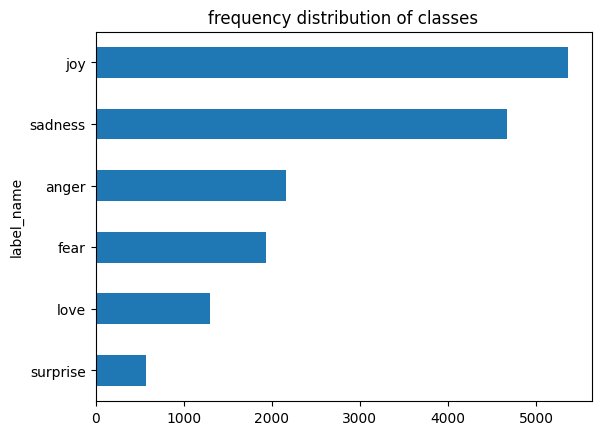

In [ ]:
#identifying class distribution

import  matplotlib.pyplot as plt

df["label_name"]. value_counts(ascending=True).plot.barh()
plt.title("frequency distribution of classes")
plt.show()

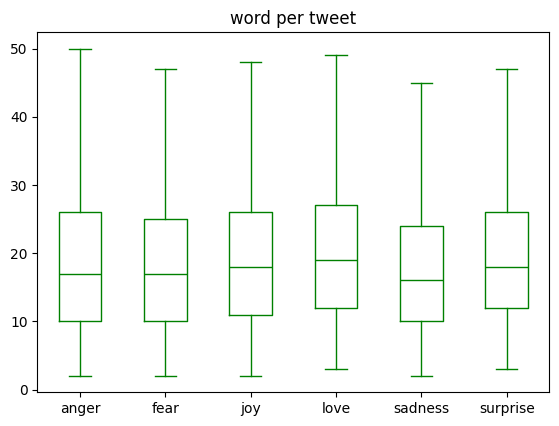

In [ ]:
#number of token per label

df["word per tweet"] = df["text"].str.split().apply(len)
df.boxplot("word per tweet",by= "label_name",grid = False,showfliers= False,color ="green")
plt.suptitle("")
plt.xlabel("")
plt.show()

In [ ]:
emotions.reset_format()

In [ ]:
#character tokenization
text = "Tokenization is a crucial step in NLP "
tokenized_txt = list(text)
print(tokenized_txt)

#encoding

token2idx = {ch: idx for idx, ch in enumerate(sorted(set(tokenized_txt)))}

print(token2idx)
input_ids = [token2idx[token] for token in tokenized_txt]
print(input_ids)

['T', 'o', 'k', 'e', 'n', 'i', 'z', 'a', 't', 'i', 'o', 'n', ' ', 'i', 's', ' ', 'a', ' ', 'c', 'r', 'u', 'c', 'i', 'a', 'l', ' ', 's', 't', 'e', 'p', ' ', 'i', 'n', ' ', 'N', 'L', 'P', ' ']
{' ': 0, 'L': 1, 'N': 2, 'P': 3, 'T': 4, 'a': 5, 'c': 6, 'e': 7, 'i': 8, 'k': 9, 'l': 10, 'n': 11, 'o': 12, 'p': 13, 'r': 14, 's': 15, 't': 16, 'u': 17, 'z': 18}
[4, 12, 9, 7, 11, 8, 18, 5, 16, 8, 12, 11, 0, 8, 15, 0, 5, 0, 6, 14, 17, 6, 8, 5, 10, 0, 15, 16, 7, 13, 0, 8, 11, 0, 2, 1, 3, 0]


In [ ]:
#One hot-encoding
import  torch
import torch.nn.functional as F
input_ids = torch.tensor(input_ids)
one_hot_encoding =  F.one_hot(input_ids,num_classes = len(token2idx))
one_hot_encoding.shape


print(f"tokenizer index: {tokenized_txt[0]}")
print( f"tensor index : {input_ids[0]}")
print(f"one hot : {one_hot_encoding[0]}")

tokenizer index: T
tensor index : 4
one hot : tensor([0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])


In [ ]:
#subword Tokenization
from transformers import AutoTokenizer
model_ckpt = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)
encoded_txt = tokenizer(text)

print(encoded_txt)

#converting ids back to tokens
tokens = tokenizer.convert_ids_to_tokens(encoded_txt.input_ids)
print(tokens)
#converting tokens back to string
print(tokenizer.convert_tokens_to_string(tokens))
# model's vocabulary size
tokenizer.vocab_size
#model's context size
tokenizer.model_max_length

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

{'input_ids': [101, 19204, 3989, 2003, 1037, 10232, 3357, 1999, 17953, 2361, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}
['[CLS]', 'token', '##ization', 'is', 'a', 'crucial', 'step', 'in', 'nl', '##p', '[SEP]']
[CLS] tokenization is a crucial step in nlp [SEP]


512

In [ ]:
#Tokenizing a dataset
def tokenize(batch):
    return tokenizer(batch["text"],padding = True,truncation = True)

print (tokenize(emotions["train"][ :2]))
emotions_encoded = emotions.map(tokenize,batched = True,batch_size = None)

print(emotions_encoded["train"].column_names)

{'input_ids': [[101, 1045, 2134, 2102, 2514, 26608, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [101, 1045, 2064, 2175, 2013, 3110, 2061, 20625, 2000, 2061, 9636, 17772, 2074, 2013, 2108, 2105, 2619, 2040, 14977, 1998, 2003, 8300, 102]], 'token_type_ids': [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]}


Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask']


In [ ]:
#transormer as feature extractor
from transformers import AutoModel
model_ckpt = "Distilbert-base-uncased"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = AutoModel.from_pretrained(model_ckpt).to(device)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: Distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
#extracting hidden states
text = " sample text for the model"
input = tokenizer(text,return_tensors = "pt")
#print(f"input shape:{input['input_ids'].size()}")

input = {k:v.to(device) for k,v in input.items()}
with torch.no_grad():
     Outputs = model(**input)
print(Outputs)

BaseModelOutput(last_hidden_state=tensor([[[-0.3088, -0.2367,  0.0315,  ..., -0.1672,  0.0835,  0.4591],
         [ 0.2906, -0.0482, -0.2277,  ..., -0.2244,  0.3485, -0.0169],
         [ 0.0320,  0.2589,  0.1110,  ..., -0.4094, -0.1815,  0.1663],
         ...,
         [-0.8391, -0.5571,  0.0439,  ..., -0.1499, -0.0506,  0.2238],
         [-0.1668, -0.2891, -0.1848,  ..., -0.5155, -0.1361, -0.0109],
         [ 0.9333,  0.0637, -0.4691,  ...,  0.3034, -0.7328, -0.2396]]]), hidden_states=None, attentions=None)


In [ ]:
Outputs.last_hidden_state.size()
Outputs.last_hidden_state[:,0].size()

torch.Size([1, 768])

In [16]:
#extracting hidden state from a dataset
def extract_hidden_state(batch):
    inputs = {k:v.to(device) for k,v in batch.items() if k in tokenizer.model_input_names}
    with torch.no_grad():
         last_hidden_state = model(**inputs).last_hidden_state
    return {"hidden state":last_hidden_state[:,0].cpu().numpy()}

emotions_encoded.set_format("torch",columns=["input_ids","attention_mask","label"])


emotions_hidden = emotions_encoded.map(extract_hidden_state,batched = True)
emotions_hidden["train"].column_names

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

['text',
 'label',
 'input_ids',
 'token_type_ids',
 'attention_mask',
 'hidden state']

In [19]:
#Creating feature matrix
import numpy as np
x_train = np.array(emotions_hidden["train"]["hidden state"])
x_valid = np.array(emotions_hidden["validation"]["hidden state"])
y_train = np.array(emotions_hidden["train"]["label"])
y_valid = np.array(emotions_hidden["validation"]["label"])

x_train.shape,x_valid.shape

((16000, 768), (2000, 768))

In [20]:
#visualizing the training set(hidden state)
from umap import UMAP
from sklearn.preprocessing import MinMaxScaler
x_scaled = MinMaxScaler(). fit_transform(x_train)

mapper = UMAP (n_components = 2, metric = "cosine").fit(x_scaled)
df_emb = pd.DataFrame(mapper.embedding_, columns=["x","y"])
df_emb["label"] = y_train
df_emb.head()

,x,y,label
0,4.153252,3.485719,0
1,-3.192616,4.707383,0
2,5.231695,6.848224,3
3,-2.477571,6.650867,2
4,-3.351053,6.576749,3


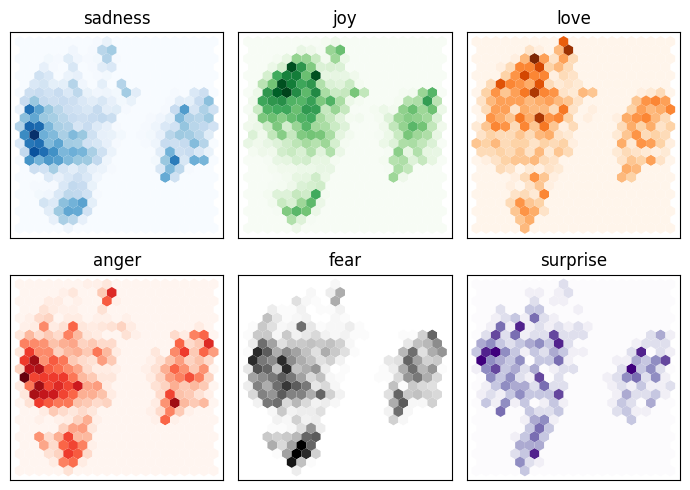

In [31]:
#plotting the density points
fig,axes =plt.subplots(2,3 ,figsize =( 7,5 ))
axes = axes.flatten()
camps = ["Blues","Greens","Oranges","Reds","Greys","Purples"]
labels = emotions["train"]. features["label"].names


for i ,(cmap,label) in enumerate (zip(camps,labels)):
    df_emb_sub = df_emb.query(f"label == {i}")
    axes[i].hexbin(df_emb_sub["x"],df_emb_sub["y"],cmap = cmap,gridsize = 20,linewidths = (0,))

    axes[i].set_title(label)
    axes[i].set_xticks([]),axes[i].set_yticks([])

plt.tight_layout()
plt.show()